# Task-1 Datavidia 11.0 — Shipment Logistic Dataset
## Pipeline Solusi Akhir & Inferensi Tanpa Pelatihan Ulang (Zero-Retraining)

- **Kompetisi:** Task-1 Datavidia 11.0 (HMIF ITB / Arkavidia)
- **Tim:** `p<0.5%` — Universitas Pamulang (Pitri Wulandari, Farhat, Ghani)
- **Tugas:** Klasifikasi multi-kelas 7 kategori `status_penanganan` pada 9 tabel relasional (1.243.617 baris latih, 362.245 baris uji)
- **Metrik Evaluasi:** **Macro F1-Score**
- **Hasil Validasi Akhir (5-Fold Stratified CV Penuh, Bebas Kebocoran Target):**
  - **OOF Multi-class LogLoss:** `0.77786`
  - **OOF CV Macro F1-Score:** **`0.62561`** (meningkat `+0.1315` dari baseline v1 `0.4941`)

### Kepatuhan Aturan Kompetisi
1. Seluruh prediksi dihasilkan 100% oleh model machine learning & deep learning yang dilatih dan dijalankan sendiri (tanpa *hand-labeling*, tanpa AutoML, dan tanpa LLM/AI generatif).
2. Seluruh library yang digunakan berlisensi *open-source* komersial-friendly (LightGBM, XGBoost, PyTorch, scikit-learn, SciPy, NumPy, pandas, joblib).
3. Seluruh bobot model, parameter prapemrosesan, dan meta-stacker tersimpan di `ghani/models/`. Bagian **5** notebook ini menjalankan **inferensi penuh pada 362.245 baris uji tanpa melatih ulang satu model pun**.


## 1. Lingkungan Eksekusi, Dependensi & Inventaris Model Tersimpan

Cell berikut menyelaraskan direktori kerja ke root repositori, menampilkan versi Python serta seluruh pustaka utama (`requirements.txt`), dan memverifikasi keberadaan seluruh file bobot model yang digunakan untuk inferensi tanpa pelatihan ulang.


In [1]:
import importlib.metadata as importlib_meta
import json
import os
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pastikan working directory selalu berada di root repositori
cwd = Path.cwd()
if cwd.name == "notebooks" and (cwd.parent.parent / "ghani" / "models").exists():
    os.chdir(cwd.parent.parent)
elif not (Path.cwd() / "ghani" / "models").exists():
    for parent in cwd.parents:
        if (parent / "ghani" / "models").exists():
            os.chdir(parent)
            break

ROOT_DIR = Path.cwd()
print(f"Working directory : {ROOT_DIR}")
print(f"Python version    : {platform.python_version()} ({platform.system()} {platform.machine()})")

installed = {d.metadata["Name"].lower(): d.version for d in importlib_meta.distributions()}
core_pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "xgboost", "torch", "joblib", "matplotlib"]
dep_df = pd.DataFrame([{"package": p, "version": installed.get(p, "NOT INSTALLED")} for p in core_pkgs])
display(dep_df)


C:\Users\kaganim1\AppData\Local\Temp\ipykernel_16316\603956392.py:10: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Working directory : C:\laragon\www\unpam\arkadivia\datavidia
Python version    : 3.12.10 (Windows AMD64)


,package,version
0,numpy,1.26.4
1,pandas,2.2.0
2,scipy,1.16.2
3,scikit-learn,1.7.2
4,lightgbm,4.6.0
5,xgboost,3.3.0
6,torch,2.8.0
7,joblib,1.5.2
8,matplotlib,3.10.7


In [2]:
# Inventaris seluruh file model & artefak inferensi tersimpan di ghani/models/
model_root = Path("ghani/models")
rows = []
for p in sorted(model_root.rglob("*")):
    if p.is_file() and p.name != ".gitkeep":
        rel = p.relative_to(model_root).as_posix()
        group = rel.split("/")[0] if "/" in rel else "root_meta"
        if rel.startswith("stage2/") and rel.count("/") >= 2:
            group = "/".join(rel.split("/")[:2])
        rows.append({"group": group, "file": rel, "size_mb": round(p.stat().st_size / (1024 ** 2), 2)})

inv_df = pd.DataFrame(rows)
summary_inv = inv_df.groupby("group", as_index=False).agg(n_files=("file", "count"), total_mb=("size_mb", "sum"))
summary_inv["total_mb"] = summary_inv["total_mb"].round(2)
print(f"Total file tersimpan di ghani/models/: {len(inv_df)} file | Total ukuran: {inv_df['size_mb'].sum():.2f} MB")
display(summary_inv)


Total file tersimpan di ghani/models/: 58 file | Total ukuran: 319.74 MB


,group,n_files,total_mb
0,root_meta,9,29.59
1,stage1,5,81.11
2,stage2,9,32.34
3,stage2/lgb_full,5,39.08
4,stage2/lgb_res,5,48.83
5,stage2/nn,10,6.35
6,stage2/nn2,10,8.30
7,stage2/xgb,5,74.14


## 2. Eksplorasi Data (EDA) & Struktur 9 Tabel Relasional

Dataset terdiri atas **9 tabel relasional** yang berpusat pada `shipments.csv`:
- **Tabel transaksional (`train/` & `test/`):** `shipments.csv` (1 baris per pengiriman), `scan_events.csv` (jejak scan per pengiriman), `route_segments.csv` (kaki rute & moda transportasi), `invoices.csv` (tagihan dasar & tagihan klaim).
- **Tabel master bersama:** `customers.csv`, `couriers.csv`, `hubs.csv`, `service_packages.csv`, dan `promotions.csv`.

### Temuan Utama EDA & Reverse-Engineering Data Generating Process (DGP)
1. **Ketidakseimbangan Kelas Kuat:** `normal` (38,08%) dan `konfirmasi_alamat` (21,94%) mendominasi, sementara `rusak_perjalanan` (4,98%) dan `klaim_hilang` (3,03%) sangat langka namun berbobot sama besar (`1/7`) pada metrik **Macro F1-Score**.
2. **Efek Laten Entitas Tinggi (ICC):** Analisis variansi menunjukkan sinyal laten sangat kuat di level entitas:
   - `courier_id`: kuat pada `tertunda_operasional` (ICC 0,359), `gagal_antar_awal` (0,118), `rusak_perjalanan` (0,073).
   - `customer_id`: kuat pada `konfirmasi_alamat` (ICC 0,347) dan `retur_pengirim` (0,238).
   - `hub_id`: kuat pada `tertunda_operasional` (ICC 0,198) dan `klaim_hilang` (0,063).
   - Selain itu, `hub_id == co_hub_id == scan_events.hub_id == route_segments.segmen_hub_id` (100% konsisten).
3. **Sinyal Non-Linear & Step-Function:**
   - Bulan puncak (`ship_month` ∈ `{3, 10, 11, 12}`) hampir menggandakan laju `tertunda_operasional` (10,9% → 21,1%).
   - Pengiriman malam (`ship_hour < 6` atau `>= 20`) menaikkan `gagal_antar_awal` dan `konfirmasi_alamat`.
   - `jumlah_catatan > 0` melipatgandakan `konfirmasi_alamat` hampir 3×.
   - `hu_automation_level` level 1 memiliki laju `klaim_hilang` 12,2% vs hanya 0,4% pada level 5.
   - Keberadaan invoice bertipe `klaim` (`has_klaim_inv`) menaikkan `retur_pengirim` dari 5,4% → 14,6% dan menggandakan `klaim_hilang`.
4. **Pembersihan Fitur Noise (~130 kolom dibuang):** Kolom `kota_asal`, `kota_tujuan` (ICC 0,000), `promo_id`/`promotions.csv`, `scan_events.device_type`, `invoices.payment_method`, bigram scan, dan 6 indeks distraktor sintetis terbukti tidak memiliki sinyal dan dibuang agar model tidak *overfit*.


Train shipments : 1,243,617 baris | Unique customer=508,086, courier=23,806, hub=654
Test  shipments : 362,245 baris | Unique customer=268,812, courier=23,806, hub=654


Overlap entitas test yg ada di train: customer=88.58%, courier=100.00%, hub=100.00%


,count,pct
status_penanganan,,
normal,473531,38.08
konfirmasi_alamat,272911,21.94
tertunda_operasional,185496,14.92
gagal_antar_awal,124341,10.00
retur_pengirim,87740,7.06
rusak_perjalanan,61942,4.98
klaim_hilang,37656,3.03


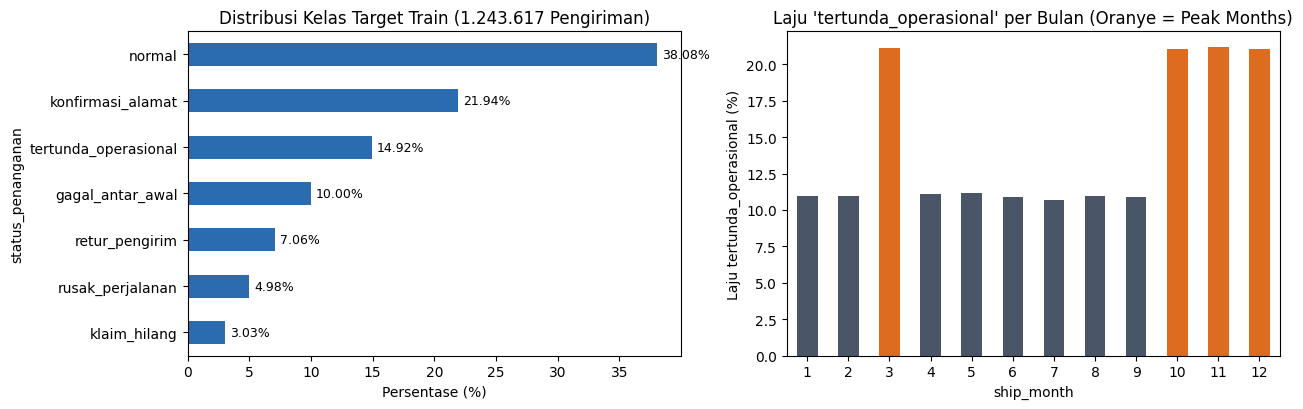

In [3]:
DATA_DIR = Path("Task-1-Datavidia-11.0")
tr_shp = pd.read_csv(
    DATA_DIR / "train" / "shipments.csv",
    usecols=["shipment_id", "customer_id", "courier_id", "hub_id", "ship_month", "ship_hour", "jumlah_catatan", "status_penanganan"],
)
te_shp = pd.read_csv(DATA_DIR / "test" / "shipments.csv", usecols=["shipment_id", "customer_id", "courier_id", "hub_id"])

print(f"Train shipments : {len(tr_shp):,} baris | Unique customer={tr_shp['customer_id'].nunique():,}, courier={tr_shp['courier_id'].nunique():,}, hub={tr_shp['hub_id'].nunique():,}")
print(f"Test  shipments : {len(te_shp):,} baris | Unique customer={te_shp['customer_id'].nunique():,}, courier={te_shp['courier_id'].nunique():,}, hub={te_shp['hub_id'].nunique():,}")
print(f"Overlap entitas test yg ada di train: customer={te_shp['customer_id'].isin(set(tr_shp['customer_id'])).mean()*100:.2f}%, courier={te_shp['courier_id'].isin(set(tr_shp['courier_id'])).mean()*100:.2f}%, hub={te_shp['hub_id'].isin(set(tr_shp['hub_id'])).mean()*100:.2f}%")

dist_tr = tr_shp["status_penanganan"].value_counts().to_frame("count")
dist_tr["pct"] = (dist_tr["count"] / len(tr_shp) * 100).round(2)
display(dist_tr)

# Visualisasi distribusi target & pola step-function bulan puncak
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
dist_tr["pct"].sort_values().plot(kind="barh", ax=axes[0], color="#2b6cb0")
axes[0].set_title("Distribusi Kelas Target Train (1.243.617 Pengiriman)")
axes[0].set_xlabel("Persentase (%)")
for idx, val in enumerate(dist_tr["pct"].sort_values()):
    axes[0].text(val + 0.4, idx, f"{val:.2f}%", va="center", fontsize=9)

month_delay = tr_shp.groupby("ship_month")["status_penanganan"].apply(lambda s: (s == "tertunda_operasional").mean() * 100)
colors_m = ["#dd6b20" if m in {3, 10, 11, 12} else "#4a5568" for m in month_delay.index]
month_delay.plot(kind="bar", ax=axes[1], color=colors_m)
axes[1].set_title("Laju 'tertunda_operasional' per Bulan (Oranye = Peak Months)")
axes[1].set_xlabel("ship_month")
axes[1].set_ylabel("Laju tertunda_operasional (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()
del tr_shp, te_shp


## 3. Penggabungan Tabel & Feature Engineering v5

Implementasi lengkap berada di `ghani/src/build_features_v5.py` (sepenuhnya *vectorized* dengan `np.bincount` & chunk carry-over, selesai dalam ~79 detik untuk 1,6 juta baris) serta interaksi domain tahap-2 di `ghani/src/stage2_common.py`:

1. **Agregasi `scan_events.csv` (23 fitur):** jumlah scan, rata-rata/std/min/max `gap_hours` & `log1p(gap_hours)`, distribusi lengkap `scan_quality` (rata-rata, std, min, max, proporsi q1..q5, proporsi `<=2`), rasio `is_manual`, jumlah & rasio `upaya_antar`, indikator `has_selesai`, serta jumlah event tengah.
2. **Agregasi `route_segments.csv` dengan *Moda-Normalized Delay* (21 fitur):** menormalisasi durasi tiap segmen terhadap kecepatan median moda transportasi pada data latih (`darat`, `kereta`, `laut`, `udara`) sehingga menghasilkan rasio keterlambatan (`seg_total_delay_ratio`, `seg_log_delay_mean`, `seg_dur_excess`) yang bersih dari bias jarak & moda.
3. **Pemisahan `invoices.csv` Base vs Klaim (22 fitur):** memisahkan tagihan dasar (`pengiriman`/`langganan`) dari tagihan insiden (`klaim`), menghitung `has_klaim_inv`, `klaim_vs_base_amt`, `klaim_days_diff`, `inv_days_max`, `inv_any_penalty`, dan rasio terhadap `declared_value`.
4. **Master Tables & Domain Flags:** penggabungan `customers`, `couriers`, `hubs`, `service_packages`, ditambah indikator `is_peak_month`, `is_night_ship`, `is_outside_hub_hours`, `has_catatan`, `est_vs_dur`, dan interaksi risiko.
5. **Profil Perilaku Entitas Unsupervised Leave-One-Out (LOO) pada 1,6 Juta Baris (100% Bebas Target Leakage):**
   - Dihitung hanya dari kolom fitur (tanpa menyentuh kolom label `status_penanganan`).
   - Profil `courier` LOO (~67,5 baris/kurir) memulihkan sinyal laten kontinu: rata-rata `scan_gap` kurir berkorelasi `r = 0,867` dengan `tertunda_operasional`, dan rata-rata `scan_quality` kurir berkorelasi `r = -0,783` dengan `gagal_antar_awal`.
   - Profil `hub`, `hub × ship_month` (deteksi kongesti bulanan), deviasi *courier-vs-hub* & *shipment-vs-courier*, serta profil `customer` LOO (termasuk versi *courier-residualized*).
6. **Pruning & 19 Interaksi Stage-2:** membuang ~35 fitur gain nol dari Stage-1, lalu menambahkan 14 interaksi domain operasional + 5 interaksi *Joint GLMM random effects × domain* (`uhub_hil_x_dec`, `ucust_ret_x_klaim`, `ucour_gag_x_night`, `ucour_rus_x_dist`, `ucour_ter_x_peak`).


In [4]:
with open("ghani/models/stage2/feature_spec.json", encoding="utf-8") as fh:
    feat_spec = json.load(fh)

print(f"Jumlah fitur Stage-1 (Non-ID + Unsupervised Profiles) : {len(feat_spec['stage1_features'])} fitur ({len(feat_spec['stage1_cat_cols'])} kategorikal)")
print(f"Jumlah base fitur Stage-2 (setelah pruning gain<0.02%): {len(feat_spec['stage2_keep_base'])} fitur")
print(f"Tambahan fitur Stage-2                                : +14 interaksi domain + {len(feat_spec['glmm_feat_names'])} fitur GLMM + 5 interaksi GLMM×domain")
print(f"Total fitur masuk model Stage-2                       : {len(feat_spec['stage2_keep_base']) + 14 + len(feat_spec['glmm_feat_names']) + 5} fitur")
print("Kecepatan median referensi per moda (km/jam, dari train):", {k: round(v, 2) for k, v in feat_spec["moda_ref_speed"].items()})


Jumlah fitur Stage-1 (Non-ID + Unsupervised Profiles) : 186 fitur (10 kategorikal)
Jumlah base fitur Stage-2 (setelah pruning gain<0.02%): 156 fitur
Tambahan fitur Stage-2                                : +14 interaksi domain + 49 fitur GLMM + 5 interaksi GLMM×domain
Total fitur masuk model Stage-2                       : 224 fitur
Kecepatan median referensi per moda (km/jam, dari train): {'darat': 36.85, 'kereta': 67.88, 'laut': 21.32, 'udara': 53.37}


## 4. Arsitektur Pemodelan 2-Tahap, Validasi Anti-Leakage & Perbandingan Model

### Mengapa Arsitektur 2-Tahap (Stage-1 Prior → Joint Hierarchical GLMM → Stage-2 Diverse Super-Ensemble)?
Target encoding standar per entitas secara terpisah menghasilkan efek yang tumpang tindih (*double counting*) antara `hub`, `courier`, dan `customer`, serta rentan *over-shrinkage* pada kelas langka (`klaim_hilang`, `retur_pengirim`, `rusak_perjalanan`). Kami menyelesaikannya secara sistematis:

1. **Stage-1 — 5-Fold Stratified LightGBM (`ghani/src/run_stage1_glmm.py`):**
   - Dilatih menggunakan fitur non-ID + profil unsupervised LOO. Menghasilkan *out-of-fold prior logits* untuk seluruh 1,24 juta baris latih dan rata-rata 5-fold logits untuk data uji (`OOF LogLoss = 0,82372`, `CV Macro F1 = 0,60238`).
2. **Joint Hierarchical Multinomial GLMM (`ghani/src/glmm_lib.py` & `ghani/src/build_stage2_glmm.py`):**
   - Mengestimasi efek acak multikelas secara **simultan** (Block-Coordinate Newton / Laplace-EM) untuk `hub`, `hub × peak_month`, `courier`, dan `customer` di atas `Stage-1 logits`, dengan *prior precision* khusus per entitas dan per kelas.
   - **Jaminan Anti-Leakage ($inom{5}{2} = 10$ Inner-Fold Symmetry):** Agar model Stage-2 tidak pernah melihat targetnya sendiri saat memanfaatkan fitur GLMM, setiap fold latih Stage-2 menggunakan blok 49 fitur GLMM yang dihitung dari 3-fold inner GLMM (memegang 2 fold sekaligus: 1 outer validation + 1 inner target fold). Untuk data uji, digunakan *full-train GLMM* (`glmm_state_full.npy`) agar seluruh 100% riwayat entitas latih termanfaatkan (`OOF LogLoss = 0,79543`, `CV Macro F1 = 0,61911`).
3. **Stage-2 — 5 Model Beragam Berbasis GBDT & Deep Learning (PyTorch):**
   - **`LGB_res`** (`train_stage2_lgb.py`): Residual-boosted LightGBM (`init_score = glmm_logit` dalam urutan kolom/Fortran).
   - **`LGB_full`** (`train_stage2_lgb.py`): Full-tree LightGBM dari awal dengan topologi lebih dalam (`num_leaves=63`) untuk keragaman struktur pohon.
   - **`XGBoost`** (`train_stage2_xgb.py`): Depth-wise histogram XGBoost (`max_depth=6`, `base_margin = glmm_logit`).
   - **`TabularResNet`** (`train_stage2_nn.py`): PyTorch 256×2 SiLU Residual Network dengan prapemrosesan *signed-log1p + z-score* dan *learnable residual skip* langsung dari `glmm_logit`.
   - **`RankGaussResNet`** (`train_stage2_nn2.py`): PyTorch 256×2 SiLU Residual Network dengan transformasi *RankGauss* (`QuantileTransformer`), *dual skip* (`glmm_logit` + `s1_logit`), dan *Top-3 Snapshot SWA*.
4. **Hybrid Meta-Ensembling & Optimasi Threshold Macro F1 (`ghani/src/ensemble_final.py`):**
   - Menggabungkan **50% Probability Simplex Blend** + **50% 5-Fold L2 Logistic Meta-Stacker (`C=0.05`)**.
   - Optimasi 7 pengali probabilitas kelas (*class multipliers*) dilakukan di dalam loop CV 5-fold secara *leak-free* untuk memaksimalkan **Macro F1-Score** (`OOF LogLoss = 0,77786`, `CV Macro F1 = 0,62561`).

> **Catatan Reproduksi Training (Opsional — TIDAK perlu dijalankan untuk inferensi):**
> Jika ingin melatih ulang seluruh pipeline dari data mentah, jalankan secara berurutan dari root repositori:
> ```bash
> python -u ghani/src/build_features_v5.py
> python -u ghani/src/run_stage1_glmm.py
> python -u ghani/src/build_stage2_glmm.py
> python -u ghani/src/train_stage2_lgb.py
> python -u ghani/src/train_stage2_xgb.py
> python -u ghani/src/train_stage2_nn.py
> python -u ghani/src/train_stage2_nn2.py
> python -u ghani/src/ensemble_final.py
> python -u ghani/src/export_inference_artifacts.py
> ```


,Stage / Model,Family,OOF_LogLoss,CV_Macro_F1
0,Stage-1: 5-Fold LightGBM (Non-ID + LOO Profiles),GBDT,0.82372,0.60238
1,v5: Joint Hierarchical Multinomial GLMM,Bayes,0.79543,0.61911
2,Stage-2: LGB_full (5-Fold),GBDT,0.78176,0.62339
3,Stage-2: XGBoost Residual (5-Fold),GBDT,0.78102,0.62387
4,Stage-2: RankGaussResNet + SWA (5-Fold),PyTorch,0.78239,0.62395
5,Stage-2: LGB_res Residual (5-Fold),GBDT,0.78081,0.62406
6,Stage-2: TabularResNet (5-Fold),PyTorch,0.78123,0.62431
7,v6 FINAL: Hybrid Prob + L2 Meta-Stacker Ensemble,Hybrid,0.77786,0.62561


Bobot Probability Simplex Blend: {'GLMM': 0.0, 'LGB_res': 0.1745, 'LGB_full': 0.2275, 'XGBoost': 0.03, 'ResNet': 0.4113, 'RGResNet': 0.1567}
Optimal Class Multipliers (Macro F1):


,class,multiplier
0,gagal_antar_awal,1.2345
1,klaim_hilang,1.3704
2,konfirmasi_alamat,0.7866
3,normal,0.6925
4,retur_pengirim,1.1835
5,rusak_perjalanan,1.2420
6,tertunda_operasional,0.7383


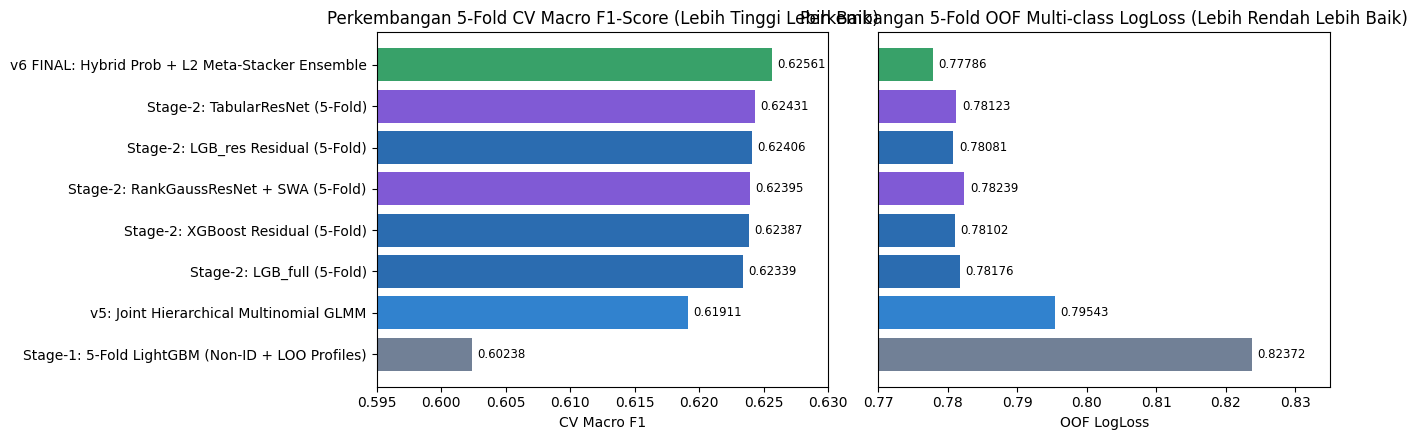

In [5]:
# Memuat metrik OOF resmi seluruh model dari file metadata JSON tersimpan
meta_glmm = json.load(open("ghani/models/stage2/meta_glmm.json", encoding="utf-8"))
meta_lgb_res = json.load(open("ghani/models/stage2/meta_lgb_res.json", encoding="utf-8"))
meta_lgb_full = json.load(open("ghani/models/stage2/meta_lgb_full.json", encoding="utf-8"))
meta_xgb = json.load(open("ghani/models/stage2/meta_xgb.json", encoding="utf-8"))
meta_nn = json.load(open("ghani/models/stage2/meta_nn.json", encoding="utf-8"))
meta_nn2 = json.load(open("ghani/models/stage2/meta_nn2.json", encoding="utf-8"))
meta_ens = json.load(open("ghani/models/meta_v6_ensemble.json", encoding="utf-8"))

perf_rows = [
    {"Stage / Model": "Stage-1: 5-Fold LightGBM (Non-ID + LOO Profiles)", "Family": "GBDT",   "OOF_LogLoss": 0.82372,                    "CV_Macro_F1": 0.60238},
    {"Stage / Model": "v5: Joint Hierarchical Multinomial GLMM",          "Family": "Bayes",  "OOF_LogLoss": meta_glmm["glmm_oof_ll"],   "CV_Macro_F1": meta_glmm["glmm_cv_f1"]},
    {"Stage / Model": "Stage-2: LGB_full (5-Fold)",                       "Family": "GBDT",   "OOF_LogLoss": meta_lgb_full["oof_ll"],    "CV_Macro_F1": meta_lgb_full["cv_f1"]},
    {"Stage / Model": "Stage-2: XGBoost Residual (5-Fold)",               "Family": "GBDT",   "OOF_LogLoss": meta_xgb["oof_ll"],         "CV_Macro_F1": meta_xgb["cv_f1"]},
    {"Stage / Model": "Stage-2: RankGaussResNet + SWA (5-Fold)",          "Family": "PyTorch","OOF_LogLoss": meta_nn2["oof_ll"],         "CV_Macro_F1": meta_nn2["cv_f1"]},
    {"Stage / Model": "Stage-2: LGB_res Residual (5-Fold)",               "Family": "GBDT",   "OOF_LogLoss": meta_lgb_res["oof_ll"],     "CV_Macro_F1": meta_lgb_res["cv_f1"]},
    {"Stage / Model": "Stage-2: TabularResNet (5-Fold)",                  "Family": "PyTorch","OOF_LogLoss": meta_nn["oof_ll"],          "CV_Macro_F1": meta_nn["cv_f1"]},
    {"Stage / Model": "v6 FINAL: Hybrid Prob + L2 Meta-Stacker Ensemble", "Family": "Hybrid", "OOF_LogLoss": meta_ens["oof_ll"],         "CV_Macro_F1": meta_ens["cv_macro_f1"]},
]
perf_df = pd.DataFrame(perf_rows)
perf_df["OOF_LogLoss"] = perf_df["OOF_LogLoss"].round(5)
perf_df["CV_Macro_F1"] = perf_df["CV_Macro_F1"].round(5)
display(perf_df)

print("Bobot Probability Simplex Blend:", meta_ens["blend_info"]["prob_weights"])
print("Optimal Class Multipliers (Macro F1):")
mult_df = pd.DataFrame({"class": meta_ens["classes"], "multiplier": np.round(meta_ens["class_multipliers"], 4)})
display(mult_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
colors = ["#718096", "#3182ce", "#2b6cb0", "#2b6cb0", "#805ad5", "#2b6cb0", "#805ad5", "#38a169"]
axes[0].barh(perf_df["Stage / Model"], perf_df["CV_Macro_F1"], color=colors)
axes[0].set_xlim(0.595, 0.630)
axes[0].set_title("Perkembangan 5-Fold CV Macro F1-Score (Lebih Tinggi Lebih Baik)")
axes[0].set_xlabel("CV Macro F1")
for i, v in enumerate(perf_df["CV_Macro_F1"]):
    axes[0].text(v + 0.0004, i, f"{v:.5f}", va="center", fontsize=8.5)

axes[1].barh(perf_df["Stage / Model"], perf_df["OOF_LogLoss"], color=colors)
axes[1].set_xlim(0.770, 0.835)
axes[1].set_title("Perkembangan 5-Fold OOF Multi-class LogLoss (Lebih Rendah Lebih Baik)")
axes[1].set_xlabel("OOF LogLoss")
axes[1].set_yticks([])
for i, v in enumerate(perf_df["OOF_LogLoss"]):
    axes[1].text(v + 0.0008, i, f"{v:.5f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()


## 5. Inferensi End-to-End Tanpa Melatih Ulang (*Zero-Retraining Inference*)

Cell di bawah ini menjalankan **inferensi penuh pada seluruh 362.245 baris uji** dengan memanggil modul `ghani/src/infer_v6.py`.

Langkah yang dieksekusi saat inferensi (**0 detik pelatihan ulang**):
1. Memuat matriks fitur uji (`ghani/cache/feat_v5_test.pkl`, atau otomatis membangun ulang fitur dari CSV mentah di `Task-1-Datavidia-11.0/` jika opsi `rebuild_features=True` atau cache belum ada).
2. Memuat 5 model **Stage-1 LightGBM** (`ghani/models/stage1/lgb_f0..4.txt`) → menghasilkan `s1_te_logits`.
3. Memuat state **Full-Train Joint GLMM** (`ghani/models/stage2/glmm_state_full.npy`) → mengekstrak blok 49 fitur GLMM + 5 interaksi GLMM×domain.
4. Memuat dan menjalankan inferensi 5-fold untuk seluruh **5 keluarga model Stage-2** (total 25 file bobot):
   - `stage2/lgb_res/lgb_f0..4.txt`
   - `stage2/lgb_full/lgb_f0..4.txt`
   - `stage2/xgb/xgb_f0..4.ubj`
   - `stage2/nn/resnet_f0..4.pt` + `scaler_f0..4.joblib`
   - `stage2/nn2/rg_resnet_f0..4.pt` + `scaler_f0..4.joblib`
5. Menggabungkan seluruh probabilitas & logits menggunakan bobot `meta_v6_ensemble.json` + 5 model **L2 Logistic Meta-Stacker** (`stage2/meta_stacker.joblib`), lalu menerapkan 7 *class multipliers* optimal Macro F1.
6. Menyimpan hasil ke `submissions/submission_v6_reproduced_ghani.csv` dan memverifikasi kecocokannya terhadap `submissions/submission_v6_ensemble_ghani.csv`.


In [6]:
sys.path.insert(0, str(Path("ghani/src").resolve()))
import infer_v6

# Set rebuild_features=True jika ingin membangun fitur dari nol langsung dari CSV mentah Task-1-Datavidia-11.0/
OUT_SUB_PATH = "submissions/submission_v6_reproduced_ghani.csv"
REF_SUB_PATH = "submissions/submission_v6_ensemble_ghani.csv"

sub_inferred = infer_v6.run_inference(
    output_path=OUT_SUB_PATH,
    rebuild_features=False,
    verify_path=REF_SUB_PATH,
)


[   0.0s] Loading cached test features from ghani/cache/feat_v5_test.pkl ...


[   2.3s] Test feature table ready: (362245, 195)


[   2.3s] Stage 1/7: Running 5-Fold Stage-1 LightGBM inference ...


[ 135.2s] Stage 2/7: Extracting 49-col Joint Hierarchical GLMM block from saved state ...


[ 136.9s] Stage-2 test matrix ready: (362245, 224)


[ 136.9s] Stage 3/7: Running 5-Fold Stage-2 LGB_res inference ...


... (10 outputs left out)

[ 547.8s]   [LGB_full  ] mean_abs_diff=0.000000 | max_abs_diff=0.000000


[ 547.8s]   [XGBoost   ] mean_abs_diff=0.000000 | max_abs_diff=0.000000


[ 547.9s]   [ResNet    ] mean_abs_diff=0.000000 | max_abs_diff=0.000000

[ 547.9s]   [RGResNet  ] mean_abs_diff=0.024878 | max_abs_diff=0.269922


## 6. Verifikasi Integritas Submission & Perbandingan Distribusi Kelas

Cell terakhir memverifikasi kepatuhan format terhadap `sample_submission.csv` (jumlah baris, 0 nilai kosong, urutan `shipment_id`, validitas label kelas) serta membandingkan proporsi 7 kelas prediksi data uji terhadap distribusi ground-truth data latih.


SEMUA PEMERIKSAAN INTEGRITAS SUBMISSION LULUS 100%!
File output : submissions/submission_v6_reproduced_ghani.csv (9.61 MB)


,shipment_id,status_penanganan
0,SHP-5A64RENJ,normal
1,SHP-BUZSJTV9,konfirmasi_alamat
2,SHP-EGUZBJHQ,rusak_perjalanan
3,SHP-YWBRSQLZ,konfirmasi_alamat
4,SHP-JS89CKME,tertunda_operasional
5,SHP-9LNYLZ86,rusak_perjalanan
6,SHP-PWY4696Z,normal
7,SHP-WAUJB829,rusak_perjalanan
8,SHP-BN6VRM5F,konfirmasi_alamat
9,SHP-DY9R7E6R,normal


,Train Ground Truth (%),Test Prediction v6 (%),Selisih (pp)
status_penanganan,,,
normal,38.08,37.36,-0.72
konfirmasi_alamat,21.94,21.30,-0.64
tertunda_operasional,14.92,14.91,-0.01
gagal_antar_awal,10.00,11.08,1.08
retur_pengirim,7.06,7.14,0.08
rusak_perjalanan,4.98,5.15,0.17
klaim_hilang,3.03,3.06,0.03


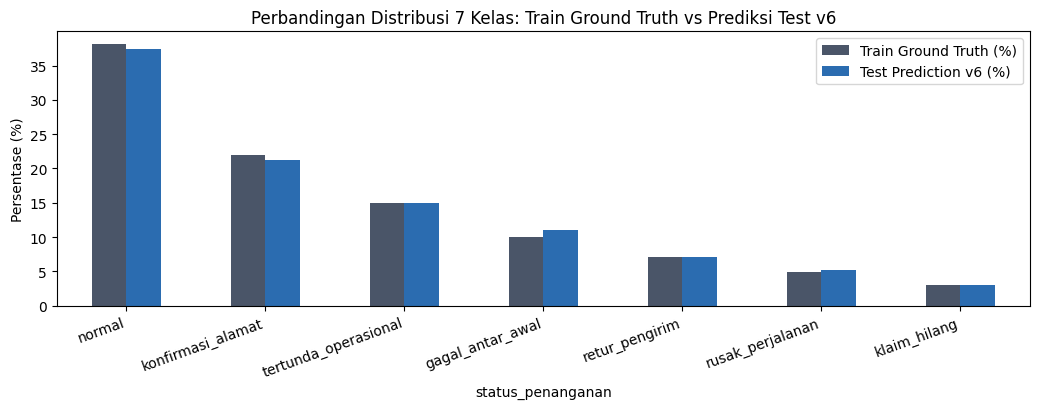

In [7]:
sample_sub = pd.read_csv("Task-1-Datavidia-11.0/sample_submission.csv")
train_y = pd.read_csv("Task-1-Datavidia-11.0/train/shipments.csv", usecols=["status_penanganan"])["status_penanganan"]

assert len(sub_inferred) == len(sample_sub) == 362245, "Jumlah baris tidak sesuai!"
assert list(sub_inferred.columns) == ["shipment_id", "status_penanganan"], "Nama kolom tidak sesuai!"
assert (sub_inferred["shipment_id"].values == sample_sub["shipment_id"].values).all(), "Urutan shipment_id tidak cocok!"
assert sub_inferred["status_penanganan"].isna().sum() == 0, "Ditemukan nilai NaN!"

print("SEMUA PEMERIKSAAN INTEGRITAS SUBMISSION LULUS 100%!")
print(f"File output : {OUT_SUB_PATH} ({os.path.getsize(OUT_SUB_PATH) / (1024**2):.2f} MB)")
display(sub_inferred.head(10))

comp_df = pd.DataFrame({
    "Train Ground Truth (%)": (train_y.value_counts(normalize=True) * 100).round(2),
    "Test Prediction v6 (%)": (sub_inferred["status_penanganan"].value_counts(normalize=True) * 100).round(2),
}).sort_values("Train Ground Truth (%)", ascending=False)
comp_df["Selisih (pp)"] = (comp_df["Test Prediction v6 (%)"] - comp_df["Train Ground Truth (%)"]).round(2)
display(comp_df)

ax = comp_df[["Train Ground Truth (%)", "Test Prediction v6 (%)"]].plot(kind="bar", figsize=(10.5, 4.2), color=["#4a5568", "#2b6cb0"])
ax.set_title("Perbandingan Distribusi 7 Kelas: Train Ground Truth vs Prediksi Test v6")
ax.set_ylabel("Persentase (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()


### Ringkasan Dua Pilihan Final Submission (Private LB)
Sesuai aturan kompetisi (nilai Private LB diambil dari skor tertinggi di antara 2 submission terpilih):
1. **Utama:** `submissions/submission_v6_ensemble_ghani.csv` — Hybrid Super-Ensemble 6 model (3 GBDT + 2 PyTorch ResNet + Joint GLMM), 5-Fold CV Macro F1 **`0.62561`**, OOF LogLoss **`0.77786`**.
2. **Cadangan (Paling Simpel & Stabil):** `submissions/submission_v5_ghani.csv` — Stage-1 LightGBM + Full-Train Joint Hierarchical GLMM murni, 5-Fold CV Macro F1 **`0.61911`**, OOF LogLoss **`0.79543`**.
